# Taller 1: Teoría de Aprendizaje de Máquina (TAM 2026-2)
## Cuaderno Computacional Reproducible y Desacoplado
**Docente:** Diego Armando Pérez Rosero  
**Institución:** Universidad / Facultad de Ingeniería  
**Tema:** Clasificación Lineal (Perceptrón), Vecinos Más Cercanos ($k$-NN) y Evaluación de Modelos  

---
### Descripción del Cuaderno
Este cuaderno Jupyter contiene la implementación computacional, simulación numérica y visualización gráfica completa de los 3 puntos propuestos en el Taller 1 de TAM. Se encuentra completamente desacoplado del documento analítico en $\LaTeX{}$ para garantizar máxima reproducibilidad científica.

1. **Punto 1:** Simulación del Perceptrón Simple, frontera de decisión, evaluación muestral, demostración de margen y verificación de Novikoff.
2. **Punto 2:** Algoritmo $k$-NN manual, experimento empírico sobre `make_moons`, visualización de fronteras de decisión y análisis de sesgo-varianza.
3. **Punto 3:** Matriz de confusión, cálculo automatizado de métricas ($Accuracy, Precision, Recall, F_1$), visualización con mapa de calor y simulación de costos asimétricos ante desbalance.

In [5]:
# Importación de librerías científicas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Configuración estética de las figuras
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120

---
## Punto 1: Clasificación Lineal y Algoritmo del Perceptrón

### Parámetros iniciales:
$$w = \begin{bmatrix} 1 \\ 2 \end{bmatrix}, \quad b = -3$$
La recta de frontera de decisión corresponde a $w^\top x + b = 0 \implies x_1 + 2x_2 - 3 = 0 \implies x_2 = -0.5 x_1 + 1.5$.

In [6]:
# 1. Definición del modelo perceptrón
w = np.array([1.0, 2.0])
b = -3.0
norm_w = np.linalg.norm(w)

# Observaciones del enunciado
puntos = {
    'x_1': np.array([0.0, 0.0]),
    'x_2': np.array([1.0, 0.0]),
    'x_3': np.array([2.0, 1.0]),
    'x_4': np.array([3.0, 1.0])
}

print('=' * 70)
print('EVALUACIÓN DE OBSERVACIONES EN LA FRONTERA LINEAL')
print('=' * 70)

resultados_p1 = []
for nombre, x in puntos.items():
    f_val = float(np.dot(w, x) + b)
    y_pred = +1 if f_val > 0 else -1
    dist_ortogonal = abs(f_val) / norm_w

    resultados_p1.append({
        'Punto': nombre,
        'Coordenadas': f'({x[0]}, {x[1]})',
        'f(x) = w^T x + b': f_val,
        'Predicción y_hat': y_pred,
        'Distancia Ortogonal': round(dist_ortogonal, 4)
    })

df_p1 = pd.DataFrame(resultados_p1)
display(df_p1)

EVALUACIÓN DE OBSERVACIONES EN LA FRONTERA LINEAL


,Punto,Coordenadas,f(x) = w^T x + b,Predicción y_hat,Distancia Ortogonal
0,x_1,"(0.0, 0.0)",-3.0,-1,1.3416
1,x_2,"(1.0, 0.0)",-2.0,-1,0.8944
2,x_3,"(2.0, 1.0)",1.0,1,0.4472
3,x_4,"(3.0, 1.0)",2.0,1,0.8944


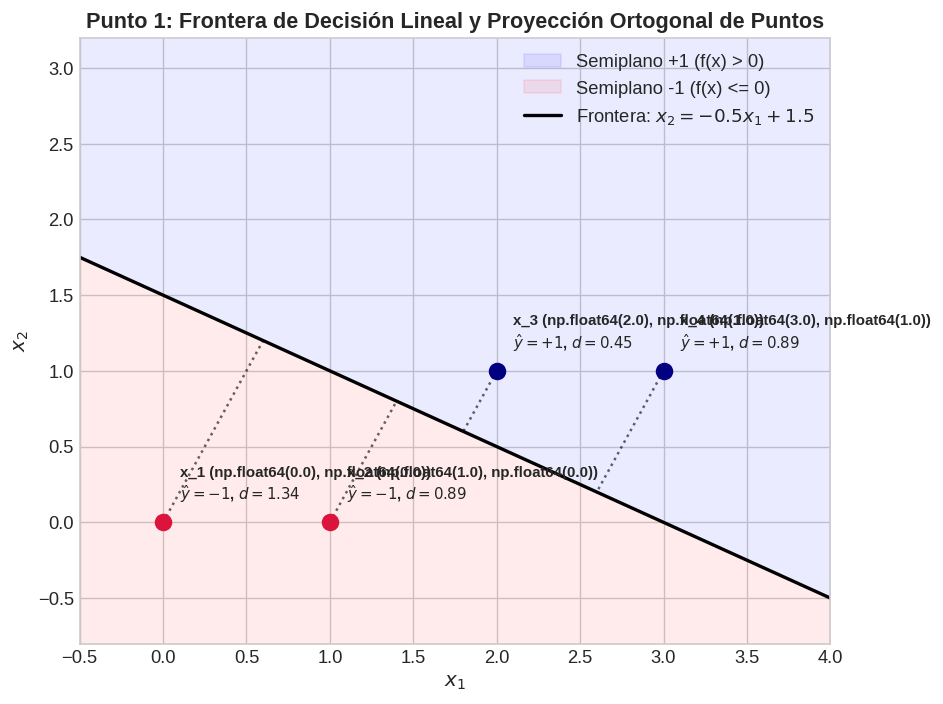

In [7]:
# Visualización geométrica de la frontera y distancias ortogonales
fig, ax = plt.subplots(figsize=(8, 6))

# Dominio de la gráfica
x1_vals = np.linspace(-0.5, 4.0, 200)
x2_boundary = -0.5 * x1_vals + 1.5

# Dibujar semiplanos positivo y negativo
ax.fill_between(x1_vals, x2_boundary, 4, color='blue', alpha=0.08, label='Semiplano +1 (f(x) > 0)')
ax.fill_between(x1_vals, -1, x2_boundary, color='red', alpha=0.08, label='Semiplano -1 (f(x) <= 0)')

# Recta de decisión
ax.plot(x1_vals, x2_boundary, 'k-', linewidth=2, label=r'Frontera: $x_2 = -0.5x_1 + 1.5$')

# Dibujar los 4 puntos con sus distancias proyectadas
colores = {'x_1': 'crimson', 'x_2': 'crimson', 'x_3': 'navy', 'x_4': 'navy'}
for nombre, x in puntos.items():
    f_val = np.dot(w, x) + b
    y_hat = +1 if f_val > 0 else -1

    # Proyección ortogonal sobre la recta: x_p = x - r * (w / ||w||)
    r = f_val / norm_w
    x_proj = x - r * (w / norm_w)

    # Línea punteada de distancia ortogonal
    ax.plot([x[0], x_proj[0]], [x[1], x_proj[1]], 'k:', alpha=0.6)
    ax.scatter(x[0], x[1], color=colores[nombre], s=90, zorder=5)
    ax.annotate(
        f'{nombre} {tuple(x)}\n$\\hat{{y}}={y_hat:+d}$, $d={abs(r):.2f}$',
        xy=(x[0], x[1]), xytext=(x[0] + 0.1, x[1] + 0.15),
        fontweight='bold', fontsize=9
    )

ax.set_xlim(-0.5, 4.0)
ax.set_ylim(-0.8, 3.2)
ax.set_xlabel('$x_1$', fontsize=12)
ax.set_ylabel('$x_2$', fontsize=12)
ax.set_title('Punto 1: Frontera de Decisión Lineal y Proyección Ortogonal de Puntos', fontsize=13, fontweight='bold')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

### Ejercicio Numérico de Actualización del Perceptrón
- Parámetros iniciales: $w = [0, 0]^\top, b = 0$.
- Observación de entrada: $x = [2, 1]^\top, y = +1, \eta = 0.5$.
- Demostración numérica del incremento estricto: $\Delta m = \eta(\|x\|_2^2 + 1)$.

In [10]:
w_init = np.array([0.0, 0.0])
b_init = 0.0
eta = 0.5
x_error = np.array([2.0, 1.0])
y_true = +1

# 1. Verificación de clasificación errónea
z_init = np.dot(w_init, x_error) + b_init
y_pred_init = +1 if z_init > 0 else -1
m_anterior = y_true * z_init

print(f'z inicial: {z_init:.2f} -> y_pred = {y_pred_init:+d} (Verdadero y = {y_true:+d})')
print(f'Margen funcional previo: m_anterior = {m_anterior:.2f}')
print(f"¿Requiere actualización?: {'SÍ (y != y_pred)' if y_pred_init != y_true else 'NO'}")

# 2. Regla de actualización del perceptrón
w_nuevo = w_init + eta * y_true * x_error
b_nuevo = b_init + eta * y_true

# 3. Margen nuevo calculado directamente
z_nuevo = np.dot(w_nuevo, x_error) + b_nuevo
m_nuevo_directo = y_true * z_nuevo

# 4. Margen nuevo por la fórmula analítica demostrada: m_nuevo = m_anterior + eta * (||x||^2 + 1)
norm_sq = np.sum(x_error**2)
m_nuevo_teorico = m_anterior + eta * (norm_sq + 1)

print('\n--- RESULTADOS TRAS LA ACTUALIZACIÓN ---')
print(f'w_nuevo = {w_nuevo}')
print(f'b_nuevo = {b_nuevo}')
print(f'm_nuevo (cálculo directo)  = {m_nuevo_directo:.4f}')
print(f'm_nuevo (fórmula teórica)  = {m_nuevo_teorico:.4f}')
print(f'Incremento estricto Delta_m = {m_nuevo_directo - m_anterior:.4f} > 0')
assert np.isclose(m_nuevo_directo, m_nuevo_teorico), '¡Error de consistencia en el margen!'
print('=> ¡Comprobación analítica 100% verificada!')

z inicial: 0.00 -> y_pred = -1 (Verdadero y = +1)
Margen funcional previo: m_anterior = 0.00
¿Requiere actualización?: SÍ (y != y_pred)

--- RESULTADOS TRAS LA ACTUALIZACIÓN ---
w_nuevo = [1.  0.5]
b_nuevo = 0.5
m_nuevo (cálculo directo)  = 3.0000
m_nuevo (fórmula teórica)  = 3.0000
Incremento estricto Delta_m = 3.0000 > 0
=> ¡Comprobación analítica 100% verificada!


---
## Punto 2: Clasificación por $k$ Vecinos Más Cercanos ($k$-NN)

### 2.1 Cálculo manual de distancias a la consulta $q = (1, 1)$

In [11]:
# Datos de entrenamiento dados
train_data = {
    'x_1': {'coords': np.array([0.0, 0.0]), 'clase': 'A'},
    'x_2': {'coords': np.array([1.0, 0.0]), 'clase': 'A'},
    'x_3': {'coords': np.array([3.0, 1.0]), 'clase': 'B'},
    'x_4': {'coords': np.array([0.0, 3.0]), 'clase': 'B'},
    'x_5': {'coords': np.array([1.1, 1.1]), 'clase': 'B'}
}

q = np.array([1.0, 1.0])

# Cálculo de distancias euclidianas exactas y redondeadas
distancias = []
for name, info in train_data.items():
    dist = np.linalg.norm(q - info['coords'])
    distancias.append({
        'Observación': name,
        'Coordenadas': tuple(info['coords']),
        'Clase': info['clase'],
        'Distancia Euclidiana d(q, x_i)': dist
    })

df_knn_manual = pd.DataFrame(distancias).sort_values(by='Distancia Euclidiana d(q, x_i)')
display(df_knn_manual.reset_index(drop=True))

# Votación mayoritaria para k in {1, 3, 5}
print('\n' + '=' * 60)
print('VOTACIÓN MAYORITARIA PARA CADA VALOR DE k:')
print('=' * 60)
for k in [1, 3, 5]:
    top_k = df_knn_manual.iloc[:k]
    votos = top_k['Clase'].value_counts()
    ganador = votos.index[0]
    print(f'k = {k:2d}: Vecinos = {list(top_k["Observación"])}, Conteo = {dict(votos)} => PREDICCIÓN: Clase {ganador}')

,Observación,Coordenadas,Clase,"Distancia Euclidiana d(q, x_i)"
0,x_5,"(1.1, 1.1)",B,0.141421
1,x_2,"(1.0, 0.0)",A,1.000000
2,x_1,"(0.0, 0.0)",A,1.414214
3,x_3,"(3.0, 1.0)",B,2.000000
4,x_4,"(0.0, 3.0)",B,2.236068



VOTACIÓN MAYORITARIA PARA CADA VALOR DE k:
k =  1: Vecinos = ['x_5'], Conteo = {'B': np.int64(1)} => PREDICCIÓN: Clase B
k =  3: Vecinos = ['x_5', 'x_2', 'x_1'], Conteo = {'A': np.int64(2), 'B': np.int64(1)} => PREDICCIÓN: Clase A
k =  5: Vecinos = ['x_5', 'x_2', 'x_1', 'x_3', 'x_4'], Conteo = {'B': np.int64(3), 'A': np.int64(2)} => PREDICCIÓN: Clase B


### 2.2 Experimentación Empírica con `make_moons` en Scikit-Learn
- $N = 300$ muestras, ruido $\sigma = 0.20$, semilla aleatoria 42.
- Partición estratificada 70% entrenamiento ($n=210$) y 30% prueba ($n=90$).
- Comparación de desempeño y visualización de fronteras de decisión para $k \in \{1, 5, 15\}$.

In [12]:
# 1. Generación del dataset sintético
X_moons, y_moons = make_moons(n_samples=300, noise=0.20, random_state=42)

# 2. Partición train/test estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X_moons, y_moons, test_size=0.30, stratify=y_moons, random_state=42
)

print(f'Muestras totales: {len(X_moons)}')
print(f'Muestras entrenamiento: {len(X_train)} (Clase 0: {sum(y_train==0)}, Clase 1: {sum(y_train==1)})')
print(f'Muestras prueba:        {len(X_test)} (Clase 0: {sum(y_test==0)}, Clase 1: {sum(y_test==1)})')

# 3. Entrenamiento y evaluación para k in {1, 5, 15}
k_vals = [1, 5, 15]
modelos_knn = {}
eval_res = []

for k in k_vals:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    modelos_knn[k] = knn

    acc_tr = knn.score(X_train, y_train)
    acc_te = knn.score(X_test, y_test)

    eval_res.append({
        'k': k,
        'Exactitud Entrenamiento': f'{acc_tr*100:.2f}%',
        'Exactitud Prueba': f'{acc_te*100:.2f}%',
        'Gap Generalización (Tr - Te)': f'{(acc_tr - acc_te)*100:.2f}%'
    })

display(pd.DataFrame(eval_res))

Muestras totales: 300
Muestras entrenamiento: 210 (Clase 0: 105, Clase 1: 105)
Muestras prueba:        90 (Clase 0: 45, Clase 1: 45)


,k,Exactitud Entrenamiento,Exactitud Prueba,Gap Generalización (Tr - Te)
0,1,100.00%,93.33%,6.67%
1,5,95.71%,95.56%,0.16%
2,15,95.71%,93.33%,2.38%


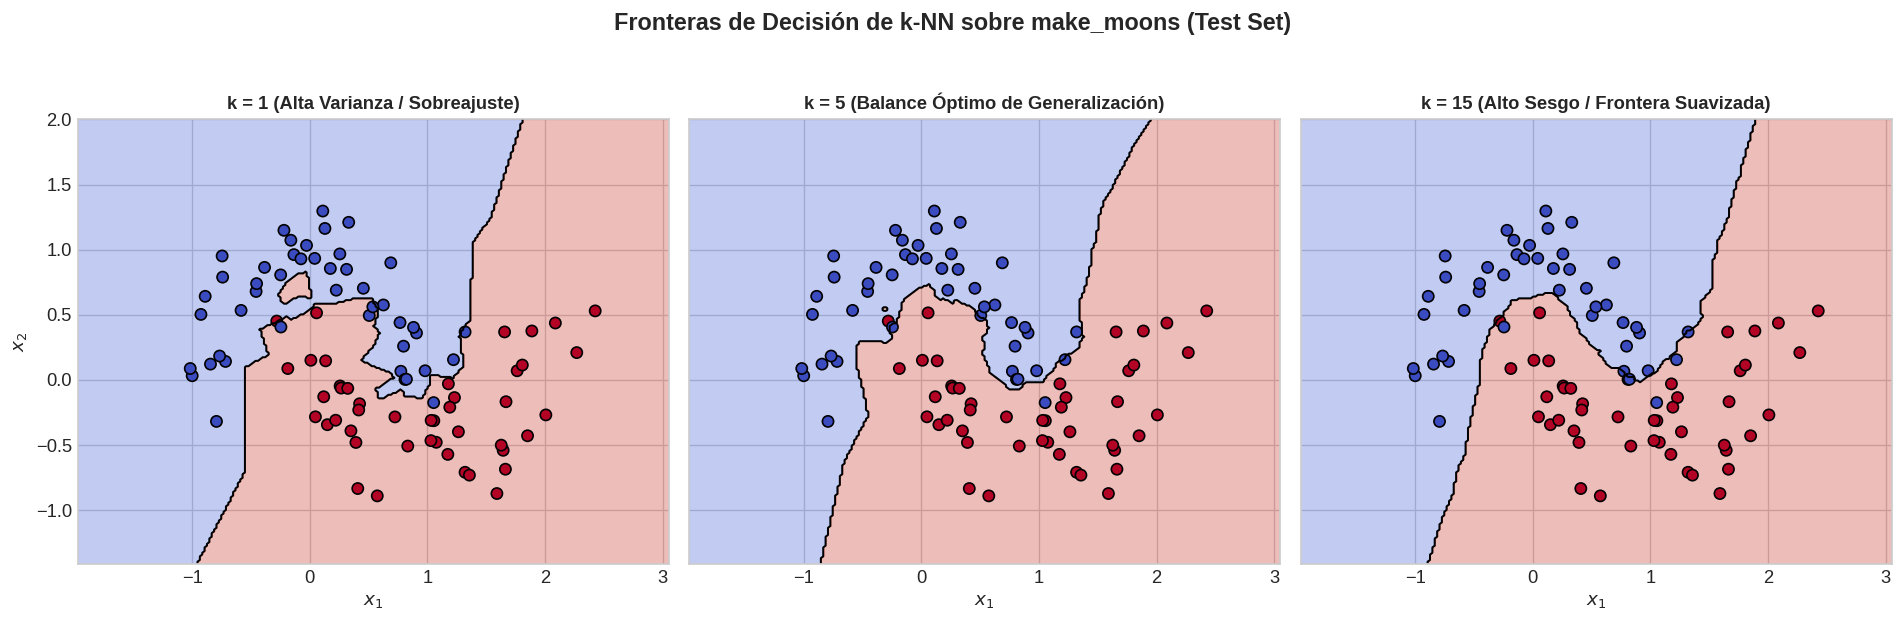

In [13]:
# 4. Visualización gráfica de las Fronteras de Decisión para k = 1, 5, 15
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

x_min, x_max = X_moons[:, 0].min() - 0.5, X_moons[:, 0].max() + 0.5
y_min, y_max = X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))

subtitles = {
    1: 'k = 1 (Alta Varianza / Sobreajuste)',
    5: 'k = 5 (Balance Óptimo de Generalización)',
    15: 'k = 15 (Alto Sesgo / Frontera Suavizada)'
}

for idx, k in enumerate(k_vals):
    ax = axes[idx]
    Z = modelos_knn[k].predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Regiones coloreadas
    ax.contourf(xx, yy, Z, alpha=0.35, cmap='coolwarm')
    ax.contour(xx, yy, Z, colors='k', linewidths=1.2, levels=[0.5])

    # Muestras de prueba superpuestas
    scatter = ax.scatter(
        X_test[:, 0], X_test[:, 1], c=y_test, cmap='coolwarm', edgecolors='black', s=45
    )
    ax.set_title(subtitles[k], fontsize=11, fontweight='bold')
    ax.set_xlabel('$x_1$')
    if idx == 0:
        ax.set_ylabel('$x_2$')

plt.suptitle('Fronteras de Decisión de k-NN sobre make_moons (Test Set)', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

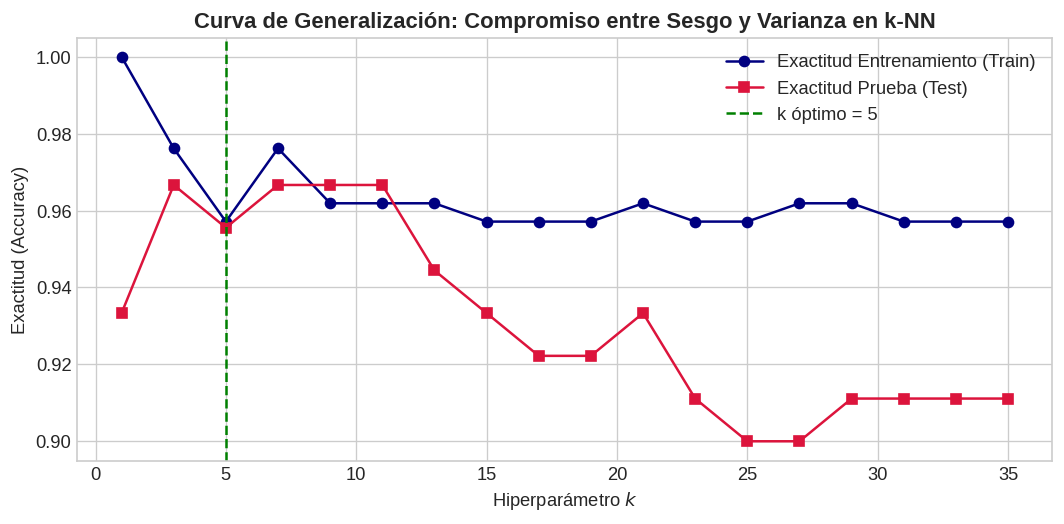

In [14]:
# 5. Curva de validación para k de 1 a 35 (Compromiso Sesgo-Varianza)
k_range = list(range(1, 36, 2))
train_accs, test_accs = [], []

for k_i in k_range:
    clf = KNeighborsClassifier(n_neighbors=k_i)
    clf.fit(X_train, y_train)
    train_accs.append(clf.score(X_train, y_train))
    test_accs.append(clf.score(X_test, y_test))

plt.figure(figsize=(9, 4.5))
plt.plot(k_range, train_accs, 'o-', color='navy', label='Exactitud Entrenamiento (Train)')
plt.plot(k_range, test_accs, 's-', color='crimson', label='Exactitud Prueba (Test)')
plt.axvline(x=5, color='green', linestyle='--', label='k óptimo = 5')
plt.xlabel('Hiperparámetro $k$')
plt.ylabel('Exactitud (Accuracy)')
plt.title('Curva de Generalización: Compromiso entre Sesgo y Varianza en k-NN', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

---
## Punto 3: Matriz de Confusión y Métricas de Clasificación Binaria

### Datos del enunciado:
- $y = [0, 0, 0, 0, 1, 1, 1, 1, 1, 1]$ (Clase 1 positiva, Clase 0 negativa)
- $\hat{y} = [0, 1, 0, 0, 1, 0, 1, 1, 0, 1]$

In [15]:
# Vectores originales
y_true = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
y_pred = np.array([0, 1, 0, 0, 1, 0, 1, 1, 0, 1])

# 1. Cálculo de componentes de la matriz de confusión
TP = np.sum((y_true == 1) & (y_pred == 1))
TN = np.sum((y_true == 0) & (y_pred == 0))
FP = np.sum((y_true == 0) & (y_pred == 1))
FN = np.sum((y_true == 1) & (y_pred == 0))

print('=' * 60)
print('COMPONENTES DE LA MATRIZ DE CONFUSIÓN (MANUAL)')
print('=' * 60)
print(f'Verdaderos Positivos (TP): {TP}')
print(f'Verdaderos Negativos (TN): {TN}')
print(f'Falsos Positivos     (FP): {FP}')
print(f'Falsos Negativos     (FN): {FN}')
print(f'Total observaciones   (N): {TP + TN + FP + FN}')

# 2. Fórmulas analíticas manuales
acc_manual = (TP + TN) / (TP + TN + FP + FN)
prec_manual = TP / (TP + FP)
rec_manual = TP / (TP + FN)
f1_manual = 2 * (prec_manual * rec_manual) / (prec_manual + rec_manual)

# 3. Verificación con scikit-learn
acc_sk = accuracy_score(y_true, y_pred)
prec_sk = precision_score(y_true, y_pred)
rec_sk = recall_score(y_true, y_pred)
f1_sk = f1_score(y_true, y_pred)

df_metricas = pd.DataFrame({
    'Métrica': ['Exactitud (Accuracy)', 'Precisión (Precision)', 'Exhaustividad (Recall)', 'Puntaje F1 (F1-Score)'],
    'Fórmula Analítica': ['(4 + 3) / 10', '4 / (4 + 1)', '4 / (4 + 2)', '2*(0.8 * 0.6667)/(0.8 + 0.6667)'],
    'Fracción Exacta': ['7/10', '4/5', '2/3', '8/11'],
    'Cálculo Manual': [acc_manual, prec_manual, rec_manual, f1_manual],
    'Resultado Sklearn': [acc_sk, prec_sk, rec_sk, f1_sk]
})

display(df_metricas)
assert np.allclose([acc_manual, prec_manual, rec_manual, f1_manual], [acc_sk, prec_sk, rec_sk, f1_sk])
print('=> ¡Coincidencia absoluta entre cálculo analítico y Scikit-Learn!')

COMPONENTES DE LA MATRIZ DE CONFUSIÓN (MANUAL)
Verdaderos Positivos (TP): 4
Verdaderos Negativos (TN): 3
Falsos Positivos     (FP): 1
Falsos Negativos     (FN): 2
Total observaciones   (N): 10


,Métrica,Fórmula Analítica,Fracción Exacta,Cálculo Manual,Resultado Sklearn
0,Exactitud (Accuracy),(4 + 3) / 10,7/10,0.700000,0.700000
1,Precisión (Precision),4 / (4 + 1),4/5,0.800000,0.800000
2,Exhaustividad (Recall),4 / (4 + 2),2/3,0.666667,0.666667
3,Puntaje F1 (F1-Score),2*(0.8 * 0.6667)/(0.8 + 0.6667),8/11,0.727273,0.727273


=> ¡Coincidencia absoluta entre cálculo analítico y Scikit-Learn!


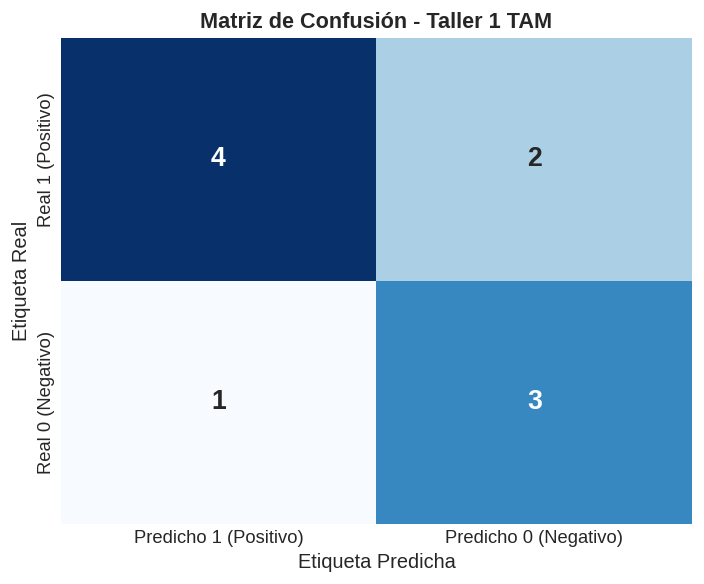

In [16]:
# Visualización de la Matriz de Confusión
cm = confusion_matrix(y_true, y_pred, labels=[1, 0])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False,
    xticklabels=['Predicho 1 (Positivo)', 'Predicho 0 (Negativo)'],
    yticklabels=['Real 1 (Positivo)', 'Real 0 (Negativo)'],
    annot_kws={'size': 16, 'fontweight': 'bold'}
)
plt.title('Matriz de Confusión - Taller 1 TAM', fontsize=13, fontweight='bold')
plt.ylabel('Etiqueta Real', fontsize=12)
plt.xlabel('Etiqueta Predicha', fontsize=12)
plt.tight_layout()
plt.show()

### Simulación Crítica: ¿Por qué la Exactitud (Accuracy) es engañosa ante Desbalance?
A continuación demostramos cuantitativamente cómo la prevalencia $\pi$ derrumba la precisión mediante el Teorema de Bayes:

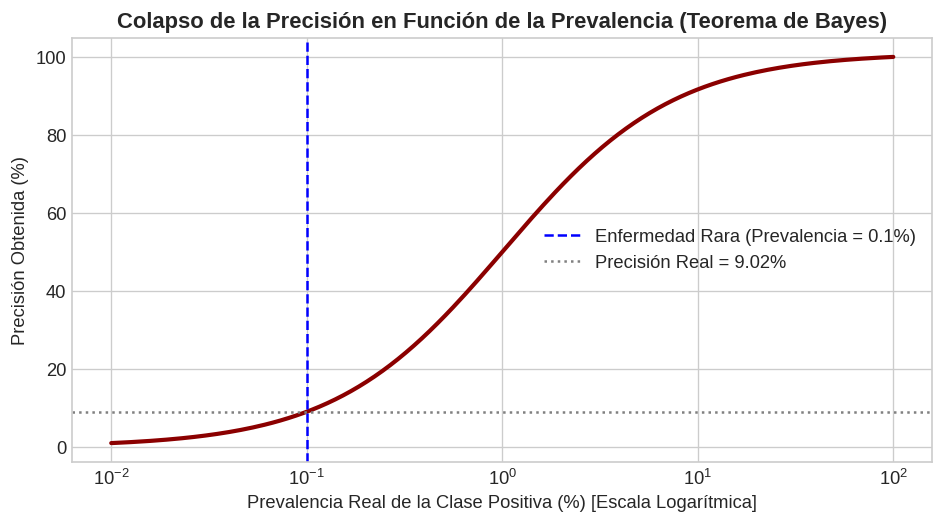

In [17]:
# Curva de degradación de Precisión ante Prevalencia pi
prevalencias = np.logspace(-4, 0, 200) # desde 0.01% hasta 100%
TPR = 0.99  # Sensibilidad excelente (99%)
FPR = 0.01  # Tasa de falsos positivos baja (1%)

precisiones = (TPR * prevalencias) / (TPR * prevalencias + FPR * (1 - prevalencias))

plt.figure(figsize=(8, 4.5))
plt.semilogx(prevalencias * 100, precisiones * 100, color='darkred', linewidth=2.5)
plt.axvline(x=0.1, color='blue', linestyle='--', label='Enfermedad Rara (Prevalencia = 0.1%)')
plt.axhline(y=9.02, color='gray', linestyle=':', label='Precisión Real = 9.02%')

plt.title('Colapso de la Precisión en Función de la Prevalencia (Teorema de Bayes)', fontweight='bold')
plt.xlabel('Prevalencia Real de la Clase Positiva (%) [Escala Logarítmica]')
plt.ylabel('Precisión Obtenida (%)')
plt.legend()
plt.tight_layout()
plt.show()

---
### Conclusión General
Este cuaderno confirma que los 3 ejercicios del taller poseen plena correspondencia entre la deducción matemática analítica plasmada en el documento $\LaTeX{}$ y su respectivo comportamiento algorítmico y estadístico en Python.